# L'attenzione a testa singola, scritta a mano su cinque parole

*Anatomia di un LLM* · capitolo 5, «L'attenzione e il blocco» · nel libro: §5.1 «Tre domande su ogni parola» · script `03-01`, `scripts/03_01_attenzione_da_zero.py`

**Dove siamo.** È il cuore del libro: l'attenzione scritta a mano, passo per passo, su una frase di cinque parole. Tutto quello che c'è nei notebook precedenti serve qui: prodotto scalare, moltiplicazione fra matrici, softmax.

Cinque parole, otto numeri per parola, e il meccanismo che permette a ognuna di
guardare le altre. Tutto quello che segue in questo libro e' questo, ripetuto.

Si esegue con `python3 scripts/03_01_attenzione_da_zero.py`
e dura circa 5 secondi.

> **Per riottenere i numeri del libro** esegui le celle in ordine, dalla prima. Il seme si fissa una volta sola, in `prepara()`: rieseguire una cella a metà cambia i numeri casuali di tutte quelle dopo.

[Apri in Colab](https://colab.research.google.com/github/fcollova/llm-anatomy/blob/main/notebooks/03_01_attenzione_da_zero.ipynb) · la prima cella scarica il codice, se non lo trova accanto.

In [ ]:
# Porta il notebook nella cartella che contiene llm_anatomy/, da dovunque
# sia stato aperto: gli script si eseguono da li', e cosi' anche le celle.
import os
import subprocess
import sys
from pathlib import Path

radice = next((p for p in [Path.cwd(), *Path.cwd().parents]
               if (p / "llm_anatomy").is_dir()), None)

if radice is None:
    # Il notebook e' stato aperto da solo, per esempio su Colab: il codice, il
    # testo e il modello addestrato si scaricano una volta, qui accanto.
    REPO, RAMO, CARTELLA = "fcollova/llm-anatomy", "main", ""
    copia = Path("anatomia-di-un-llm")
    if not copia.exists():
        esito = subprocess.run(
            ["git", "clone", "-q", "--depth", "1", "--branch", RAMO,
             f"https://github.com/{REPO}.git", str(copia)], capture_output=True)
        if esito.returncode != 0:
            raise SystemExit("Non riesco a scaricare il codice da github.com/"
                             + REPO + ": " + esito.stderr.decode()[-300:])
    radice = copia / CARTELLA

os.chdir(radice)
sys.path.insert(0, str(Path.cwd()))

In [ ]:
import math

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from llm_anatomy.utils import figura, prepara, stile_figure, titolo, verifica

prepara()

# Una frase finta, corta abbastanza da poterla stampare tutta.
frase = ["il", "gatto", "nero", "dorme", "qui"]
T = len(frase)          # quante parole
C = 8                   # quanti numeri descrivono ogni parola in ingresso
d_k = 4                 # quanti ne useremo dentro l'attenzione

x = torch.randn(1, T, C)

[ambiente] torch 2.13.0+cpu  device=cpu  threads=8  seed=1337


### Ogni parola pone tre domande su di sé

> **Nel libro, §5.1 «Tre domande su ogni parola».** Come fa una parola a tenere conto delle altre?

**Cosa guardare.** Ogni parola entra come 8 numeri ed esce come tre vettori da 4: domanda, offerta, contenuto.

**Prova a cambiare:** cambia la frase in cima al notebook, per esempio in `["la", "pasta", "va", "scolata", "al", "dente"]`, e riesegui dall'inizio.

<details><summary>Che cosa succede</summary>

Con sei parole tutte le tabelle diventano 6×6 e le percentuali cambiano; la struttura resta la stessa, triangolo compreso.

</details>

In [ ]:
titolo("Ogni parola pone tre domande su di se'")
# Le tre matrici hanno forma identica e ingresso identico. Cio' che le rende
# diverse e' soltanto il posto che occupano nella formula che viene dopo.
Wq = nn.Linear(C, d_k, bias=False)   # che cosa sto cercando
Wk = nn.Linear(C, d_k, bias=False)   # che cosa offro a chi cerca
Wv = nn.Linear(C, d_k, bias=False)   # che cosa porto, se mi scelgono
q, k, v = Wq(x), Wk(x), Wv(x)
print(f"  la frase e': {' '.join(frase)}")
print(f"  ogni parola entra come {C} numeri e diventa tre vettori da {d_k}")
print("  si chiamano query, key e value: domanda, offerta, contenuto")


Ogni parola pone tre domande su di se'
--------------------------------------
  la frase e': il gatto nero dorme qui
  ogni parola entra come 8 numeri e diventa tre vettori da 4
  si chiamano query, key e value: domanda, offerta, contenuto


### Chi si allinea con chi

**Cosa guardare.** Un numero per ogni coppia: riga chi guarda, colonna chi viene guardato. Sono ancora punteggi grezzi.

In [ ]:
titolo("Chi si allinea con chi")
# Prodotto scalare fra ogni domanda e ogni offerta: grande se puntano nella
# stessa direzione, negativo se puntano in direzioni opposte.
punteggi = q @ k.transpose(-2, -1)
print("  riga = chi guarda, colonna = chi viene guardato\n")
print("         " + " ".join(f"{p:>7}" for p in frase))
for i in range(T):
    riga = " ".join(f"{c:7.3f}" for c in punteggi[0, i].tolist())
    print(f"  {frase[i]:<6} {riga}")
print("\n  sono numeri grezzi: nessuno ha ancora detto quanto contano")


Chi si allinea con chi
----------------------
  riga = chi guarda, colonna = chi viene guardato

              il   gatto    nero   dorme     qui
  il      -0.046   0.073   0.515   0.095   0.126
  gatto   -0.061   1.158   0.888   0.409   0.172
  nero    -0.032  -1.117  -1.305  -0.616  -0.385
  dorme   -0.021  -0.765  -0.492  -0.242  -0.096
  qui     -0.075  -0.221  -0.587  -0.017  -0.107

  sono numeri grezzi: nessuno ha ancora detto quanto contano


### Perché si divide per la radice

*Questa parte non è stampata nel libro.*

**Cosa guardare.** La divisione per 2, cioè la radice di 4, dimezza l'oscillazione dei punteggi.

In [ ]:
titolo("Perche' si divide per la radice")
prima = punteggi.std()
punteggi = punteggi / math.sqrt(d_k)
print(f"  deviazione standard dei punteggi: {prima:.3f} prima, "
      f"{punteggi.std():.3f} dopo")
print(f"  la divisione e' per sqrt({d_k}) = {math.sqrt(d_k):.3f}")
print("  senza, i punteggi crescono con d_k, la softmax riceve numeri sempre")
print("  piu' distanti fra loro e finisce per dare tutto a una parola sola")


Perche' si divide per la radice
-------------------------------
  deviazione standard dei punteggi: 0.544 prima, 0.272 dopo
  la divisione e' per sqrt(4) = 2.000
  senza, i punteggi crescono con d_k, la softmax riceve numeri sempre
  piu' distanti fra loro e finisce per dare tutto a una parola sola


### Nessuno può guardare avanti

**Cosa guardare.** Il triangolo: ogni parola guarda se stessa e quelle prima, mai quelle dopo.

In [ ]:
titolo("Nessuno puo' guardare avanti")
# Il modello impara a prevedere la parola successiva: se potesse vedere il
# futuro, il compito sarebbe banale e non imparerebbe niente.
maschera = torch.ones(T, T, dtype=torch.bool).tril()
for i in range(T):
    print(f"  {frase[i]:<6} " + " ".join("guarda" if m else "  .   "
                                          for m in maschera[i].tolist()))
punteggi = punteggi.masked_fill(~maschera, float("-inf"))
print("\n  le caselle chiuse diventano meno infinito, che la softmax")
print("  trasforma in zero")


Nessuno puo' guardare avanti
----------------------------
  il     guarda   .      .      .      .   
  gatto  guarda guarda   .      .      .   
  nero   guarda guarda guarda   .      .   
  dorme  guarda guarda guarda guarda   .   
  qui    guarda guarda guarda guarda guarda

  le caselle chiuse diventano meno infinito, che la softmax
  trasforma in zero


### Da punteggi a percentuali

**Cosa guardare.** Ogni riga somma a cento, e la prima parola dà tutto a se stessa.

**Prova a cambiare:** scrivi `pesi = (10 * punteggi).softmax(dim=-1)`.

<details><summary>Che cosa succede</summary>

Le righe si irrigidiscono: `gatto` dà il 99,8 per cento a se stessa, `nero` il 99,4 a `il`. Più avanti la verifica della versione compatta fallisce, perché lei non moltiplica per dieci. È quello che fa la softmax con punteggi troppo grandi, ed è il perché della radice.

</details>

In [ ]:
titolo("Da punteggi a percentuali")
pesi = punteggi.softmax(dim=-1)
for i in range(T):
    riga = " ".join(f"{c:6.1%}" for c in pesi[0, i].tolist())
    print(f"  {frase[i]:<6} {riga}")
verifica(torch.allclose(pesi.sum(dim=-1), torch.ones(1, T), atol=1e-6),
         "ogni riga somma a cento per cento: e' una distribuzione")
verifica(pesi[0, 0, 1:].sum().item() < 1e-9,
         "la prima parola non guarda nulla oltre se stessa")


Da punteggi a percentuali
-------------------------
  il     100.0%   0.0%   0.0%   0.0%   0.0%
  gatto   35.2%  64.8%   0.0%   0.0%   0.0%
  nero    47.4%  27.5%  25.1%   0.0%   0.0%
  dorme   29.6%  20.4%  23.4%  26.5%   0.0%
  qui     21.2%  19.7%  16.4%  21.8%  20.9%
  [verifica superata] ogni riga somma a cento per cento: e' una distribuzione
  [verifica superata] la prima parola non guarda nulla oltre se stessa


### Il risultato: ogni parola diventa una miscela

**Cosa guardare.** `dorme` esce come miscela delle quattro parole che può guardare, con le percentuali della riga sopra.

In [ ]:
titolo("Il risultato: ogni parola diventa una miscela")
y = pesi @ v
i = 3
print(f"  la parola {frase[i]!r} esce come miscela di:")
for j in range(i + 1):
    print(f"    {frase[j]:<6} al {pesi[0, i, j]:.1%}")
a_mano = sum(pesi[0, i, j] * v[0, j] for j in range(T))
verifica(torch.allclose(a_mano, y[0, i], atol=1e-6),
         "rifacendo la miscela a mano si ottiene lo stesso vettore")


Il risultato: ogni parola diventa una miscela
---------------------------------------------
  la parola 'dorme' esce come miscela di:
    il     al 29.6%
    gatto  al 20.4%
    nero   al 23.4%
    dorme  al 26.5%
  [verifica superata] rifacendo la miscela a mano si ottiene lo stesso vettore


### Tutto quanto, in quattro righe

**Cosa guardare.** La verifica: la versione compatta coincide con quella fatta passo per passo.

In [ ]:
titolo("Tutto quanto, in quattro righe")
def attenzione(x, Wq, Wk, Wv):
    q, k, v = Wq(x), Wk(x), Wv(x)
    s = (q @ k.transpose(-2, -1)) / math.sqrt(q.shape[-1])
    m = torch.ones(x.shape[1], x.shape[1], dtype=torch.bool).tril()
    return s.masked_fill(~m, float("-inf")).softmax(-1) @ v

verifica(torch.allclose(attenzione(x, Wq, Wk, Wv), y, atol=1e-6),
         "la versione compatta fa esattamente quello che abbiamo fatto a mano")
print("  e' l'intera attenzione: tre proiezioni, un prodotto, una maschera,")
print("  una softmax, un altro prodotto")


Tutto quanto, in quattro righe
------------------------------
  [verifica superata] la versione compatta fa esattamente quello che abbiamo
                      fatto a mano
  e' l'intera attenzione: tre proiezioni, un prodotto, una maschera,
  una softmax, un altro prodotto


### La stessa tabella, a colori

*Questa parte non è stampata nel libro.*

**Cosa guardare.** La figura: più scura la casella, più attenzione; il triangolo bianco è la maschera.


La stessa tabella, a colori
---------------------------


  [figura] outputs/figures/03-01_mappa_attenzione.pdf


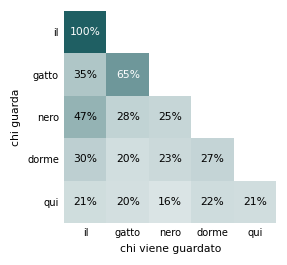

In [ ]:
# La tabella delle percentuali come mappa di colori: piu' scuro, piu' attenzione.
# Le caselle che la maschera chiude restano bianche.
titolo("La stessa tabella, a colori")
from matplotlib.colors import LinearSegmentedColormap
mappa = LinearSegmentedColormap.from_list("tasca", ["#FFFFFF", "#1F5F63"])
p = pesi[0].detach().clone()
p[~torch.ones(T, T, dtype=torch.bool).tril()] = float("nan")
fig, ax = plt.subplots(figsize=(stile_figure() * 0.62, 2.5))
ax.imshow(p, cmap=mappa, vmin=0, vmax=1)
for i in range(T):
    for j in range(i + 1):
        v = float(p[i, j])
        ax.text(j, i, f"{100 * v:.0f}%", ha="center", va="center",
                color="white" if v > 0.55 else "black")
ax.set_xticks(range(T), frase)
ax.set_yticks(range(T), frase)
ax.set_xlabel("chi viene guardato")
ax.set_ylabel("chi guarda")
ax.tick_params(length=0)
for lato in ax.spines.values():
    lato.set_visible(False)
figura(fig, "03-01_mappa_attenzione")